---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 12 · Power — The power in the wind

### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

The theme is *Power*, so here is where a growing share of Britain's electricity comes from: the
**wind over its seas**. The map is **wind power density at 100 m**, roughly the hub height of an
offshore turbine: the raw energy flowing through each square metre of swept air.

The physics is unforgiving and beautiful. Power scales with the **cube** of wind speed, so double
the wind carries **eight times** the energy. A turbine rides that cube from about 3 m/s up to its
rated speed, then holds flat until it shuts down in a storm.

This notebook then asks a cheeky question: **can a weather forecast and a textbook turbine curve
reproduce what Britain's offshore fleet really generated?** The pink line under the map is
exactly that, set against the half-hourly measurements published by Elexon, and then carried ten
days into the future.

## Method

1. **Wind.** Retrieve the 100 m wind components (`100u`, `100v`) from the ECMWF IFS **9 km (0.1°)**
   open-data forecast: the latest run out to ten days, plus the first nine hours of every run from
   the previous ten days, stitched into a 3-hourly "what the model saw" record of the recent past.
2. **Power density.** `V = √(u² + v²)` and `P = ½·ρ·V³` with standard air density `ρ = 1.225 kg/m³`,
   shown in kW/m².
3. **Farms.** Real offshore wind-farm footprints from EMODnet. Each farm samples the model wind at
   the grid point nearest its centroid.
4. **Turbine curve.** A deliberately simple one: nothing below 3 m/s, a cubic climb to full output
   at 12.5 m/s, flat to 25 m/s, then shutdown.
5. **Capacity.** Each farm's working capacity is taken from the data itself: the 99.5th percentile
   of its metered half-hourly output over the last five to six weeks (Elexon `B1610`). That
   quietly accounts for farms still under construction.
6. **Check.** Sum the farms and compare with Elexon's measured national offshore wind generation
   (`AGWS`). Nothing is fitted: the curve constants above are the only knobs, and they were not
   turned.

The estimate ignores wake losses, maintenance outages and curtailment (wind farms being paid to
turn down when the grid cannot carry the power), so it runs a little high when the fleet is busy.
The forecast half is **one deterministic run**: trust the next few days, and read the far end as
one possible future rather than a promise.

## Licence & attribution

**ECMWF Open Data** is published under **Creative Commons CC-BY-4.0**.

> © ECMWF · source www.ecmwf.int ·
> [Terms of use](https://apps.ecmwf.int/datasets/licences/general/).

**Elexon BMRS** generation data (`AGWS`, `B1610`, unit reference list) comes from the open
[Insights API](https://bmrs.elexon.co.uk/api-documentation), no key needed. Reuse is governed by
Elexon's [BMRS data licence](https://www.elexon.co.uk/bsc/data/balancing-mechanism-reporting-agent/copyright-licence-bmrs-data/).

**Wind-farm footprints** are from [EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities).

> This data product was created by EMODnet (https://emodnet.ec.europa.eu/en/), and is owned by the
> EU and licensed under the Creative Commons Attribution 4.0 International (CC BY 4.0) license.

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve 100 m wind (IFS 9 km), recent runs from the cloud mirrors |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read the GRIB into xarray |
| Elexon Insights API · EMODnet WFS | measured generation · farm footprints (plain HTTPS, standard library) |
| `numpy` · `xarray` · `shapely` · `cartopy` · `matplotlib` | power curve, geometry, projection, render |

No account needed for any of it.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data xarray netcdf4 shapely cartopy matplotlib imageio

In [2]:
import os, re, json, shutil, subprocess, warnings, collections, datetime as dt
import urllib.request, urllib.parse
import numpy as np
import xarray as xr
import earthkit.data as ekd
import shapely.geometry as sg
from shapely.ops import unary_union
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.image as mpimg
from matplotlib.colors import LinearSegmentedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
TITLEF = ["Avenir Next Demi Bold", "Arial", "DejaVu Sans"]
BG, INK, MUT, HOT, DEEP, RULE = "#ffffff", "#14213d", "#6b7385", "#ff2d7a", "#c4004f", "#dfe3ea"

### Configuration

The turbine curve constants, the map window, and the farm list. `FARMS` ties three things
together: the farm's name, the prefix of its Elexon metering units (`T_HOWAO-1` is Hornsea 1's
first unit), and the keywords that pick its footprint out of the EMODnet layer. `GROUPS` gathers
neighbouring farms under one label so the map stays readable.

In [3]:
RHO = 1.225                                   # standard air density, kg/m³
CUT_IN, RATED, CUT_OUT = 3.0, 12.5, 25.0      # turbine curve, m/s
BOX = [-16, 13, 46, 63]                       # W, E, S, N — the crop kept from each global field
DAYS_BACK = 10                                # how much recent past to stitch on
MAP_AT = None                                 # e.g. "2026-11-12T15:00" to pin the map; None = windiest hour in the next 5 days

NC  = "data/day12_wind_nwe.nc"                # cropped wind, past + forecast
GEO = "data/day12_uk_offshore_farms.geojson"  # farm footprints (EMODnet)
PNG, GIF, MP4 = "day12_power_wind.png", "day12_power_forecast.gif", "day12_power_forecast.mp4"

# farm: (Elexon unit prefixes, EMODnet name keywords)
FARMS = {
    "Moray East": (["MOWEO"], ["Moray Offshore Windfarm East"]),  "Moray West": (["MOWWO"], ["Moray West"]),
    "Beatrice": (["BEATO"], ["Beatrice Offshore"]),               "Hywind Scotland": (["HYWDW"], ["Hywind"]),
    "Aberdeen Bay": (["ABRBO"], ["Aberdeen"]),                    "Kincardine": (["KINCW"], ["Kincardine"]),
    "Seagreen": (["SGRWO"], ["Seagreen"]),                        "Neart na Gaoithe": (["NNGAO"], ["Neart"]),
    "Sofia": (["SOFOW"], ["Sofia"]),                              "Dogger Bank B": (["DBBWO"], ["Dogger Bank B"]),
    "Dogger Bank A": (["DBAWO"], ["Dogger Bank A"]),              "Hornsea 2": (["HOWBO"], ["Hornsea Project 2"]),
    "Hornsea 1": (["HOWAO"], ["Hornsea Project 1", "Hornsea 1"]), "Westermost Rough": (["WTMSO"], ["Westermost"]),
    "Humber Gateway": (["HMGTO"], ["Humber"]),                    "Triton Knoll": (["TKNEW", "TKNWW"], ["Triton"]),
    "Race Bank": (["RCBKO"], ["Race Bank"]),                      "Dudgeon": (["DDGNO"], ["Dudgeon"]),
    "Lincs": (["LNCSW"], ["Lincs"]),                              "Sheringham Shoal": (["SHRSW"], ["Sheringham"]),
    "East Anglia ONE": (["EAAO"], ["East Anglia One"]),           "Greater Gabbard": (["GRGBW"], ["Greater Gabbard"]),
    "Galloper": (["GANW"], ["Galloper"]),                         "Gunfleet Sands": (["GNFSW"], ["Gunfleet"]),
    "London Array": (["LARYW"], ["London Array"]),                "Thanet": (["THNTO"], ["Thanet"]),
    "Rampion": (["RMPNO"], ["Rampion"]),                          "Robin Rigg": (["RREW", "RRWW"], ["Robin Rigg"]),
    "Ormonde": (["OMNDW"], ["Ormonde"]),                          "Walney": (["WLNYO", "WLNYW"], ["Walney"]),
    "West of Duddon Sands": (["WDNSO"], ["West of Duddon"]),      "Barrow": (["BOWLW"], ["Barrow"]),
    "Burbo Bank": (["BRBEO", "BURBO"], ["Burbo"]),                "Gwynt y Môr": (["GYMR"], ["Gwynt"])}

# label, member farms, label lon, label lat, text alignment
GROUPS = [
    ("Moray Firth", ["Moray East", "Moray West", "Beatrice"], -1.9, 58.75, "left"),
    ("Aberdeen", ["Hywind Scotland", "Aberdeen Bay", "Kincardine"], -0.9, 57.35, "left"),
    ("Forth & Tay", ["Seagreen", "Neart na Gaoithe"], -0.9, 56.35, "left"),
    ("Dogger Bank & Sofia", ["Dogger Bank A", "Dogger Bank B", "Sofia"], 2.9, 55.45, "left"),
    ("Hornsea", ["Hornsea 1", "Hornsea 2"], 2.75, 54.0, "left"),
    ("Humber & The Wash", ["Westermost Rough", "Humber Gateway", "Triton Knoll", "Race Bank", "Dudgeon",
                           "Lincs", "Sheringham Shoal"], 2.0, 53.1, "left"),
    ("East Anglia ONE", ["East Anglia ONE"], 3.0, 52.3, "left"),
    ("Thames Estuary", ["Greater Gabbard", "Galloper", "Gunfleet Sands", "London Array", "Thanet"], 2.6, 51.35, "left"),
    ("Rampion", ["Rampion"], -0.3, 50.15, "center"),
    ("Morecambe Bay & Solway", ["Robin Rigg", "Ormonde", "Walney", "West of Duddon Sands", "Barrow"], -4.6, 54.45, "right"),
    ("Liverpool Bay", ["Burbo Bank", "Gwynt y Môr"], -4.1, 53.75, "right")]

## Retrieve — IFS 9 km 100 m wind, ten days back and ten days ahead

`resol="0p1"` gets the 9 km grid (the client defaults to 0.25°). ECMWF's own portal keeps roughly
the last four days of runs; older ones are served by the cloud mirrors, so each pull tries
`ecmwf` first and falls back to `azure`, `google`, then `aws`.

Every field is global, so each batch is cropped to north-west Europe straight away and the GRIB
is deleted. What stays on disk is one small NetCDF (about 17 MB). The cache is keyed on the run
time, so re-running on a later day fetches the new run automatically. A fresh pull is about
300 global fields, a few minutes on a decent connection.

In [4]:
from ecmwf.opendata import Client

FC_STEPS = list(range(0, 145, 3)) + list(range(150, 241, 6))      # the full 10-day forecast

def pull(run, steps):
    """One batch of 100 m wind from run `run`, cropped to BOX, as an xarray Dataset."""
    tmp = f"data/_day12_{run:%Y%m%d%H}_{steps[0]}.grib2"
    for src in ("ecmwf", "azure", "google", "aws"):
        try:
            Client(source=src).retrieve(date=f"{run:%Y-%m-%d}", time=run.hour, type="fc", step=steps,
                                        param=["100u", "100v"], resol="0p1", target=tmp)
            break
        except Exception:
            continue
    else:
        raise RuntimeError(f"no source had the {run} run")
    g = ekd.from_source("file", tmp).to_xarray().sel(longitude=slice(BOX[0], BOX[1]), latitude=slice(BOX[3], BOX[2]))
    arr = lambda n: (g[n].transpose("step", "latitude", "longitude") if "step" in g[n].dims else g[n].expand_dims("step")).values
    hours = np.asarray(steps, "timedelta64[h]")
    out = xr.Dataset({"u": (("valid_time", "latitude", "longitude"), arr("100u").astype("float32")),
                      "v": (("valid_time", "latitude", "longitude"), arr("100v").astype("float32"))},
                     coords={"valid_time": (np.datetime64(run, "ns") + hours), "latitude": g.latitude.values, "longitude": g.longitude.values})
    for f in os.listdir("data"):
        if f.startswith(os.path.basename(tmp)):
            os.remove(os.path.join("data", f))
    return out

os.makedirs("data", exist_ok=True)
try:
    latest = Client(source="ecmwf").latest(type="fc", step=240, param="100u", resol="0p1")
except Exception:                                 # offline: carry on with whatever is cached
    latest = None
cached = xr.open_dataset(NC).attrs.get("base_time") if os.path.exists(NC) else None
if latest is not None and cached != latest.isoformat():
    parts, run = [], latest - dt.timedelta(days=DAYS_BACK)
    while run < latest:                           # the recent past: first 9 h of each 12-hourly run
        parts.append(pull(run, [0, 3, 6, 9])); run += dt.timedelta(hours=12)
    for i in range(0, len(FC_STEPS), 13):         # the forecast, in batches to keep the temp GRIB small
        parts.append(pull(latest, FC_STEPS[i:i + 13]))
    wind = xr.concat(parts, "valid_time").sortby("valid_time")
    wind.attrs["base_time"] = latest.isoformat()
    if os.path.exists(NC): os.remove(NC)
    wind.to_netcdf(NC, encoding={v: {"zlib": True, "complevel": 4} for v in ("u", "v")})

wind = xr.open_dataset(NC).load()
BASE = np.datetime64(wind.attrs["base_time"], "ns")       # the forecast run
T = wind.valid_time.values
LON, LAT = wind.longitude.values, wind.latitude.values
U, V = wind.u.values, wind.v.values
SPD = np.hypot(U, V)                                      # 100 m wind speed, m/s
K0 = int(np.where(T == BASE)[0][0])                       # index of the first forecast time
print(f"IFS run {str(BASE)[:13]} UTC · {K0} past + {len(T) - K0} forecast times · {str(T[0])[:13]} → {str(T[-1])[:13]}")

To ensure the stability of our systems and to preserve resources for our operational activities (network, compute, etc.), access to the open-data portal is limited to 500 simultaneous connections. This limit helps us guarantee reliable service for our operational users, especially during periods of high demand. For added reliability, the open-data is replicated across AWS, Azure, and Google Cloud. If you experience difficulties accessing the portal directly, you can also retrieve the data from these cloud platforms.


Resolution '0p1' does not match the client resolution '0p25', using resolution '0p1' from retrieve


IFS run 2026-11-10T00 UTC · 80 past + 65 forecast times · 2026-10-31T00 → 2026-11-20T00


## Farm footprints — EMODnet

The EMODnet Human Activities wind-farm layer has a polygon for every lease area. Keep the British
ones that are producing or under construction, merge the pieces of each farm, and note the
centroid. A slimmed copy is saved beside the notebook so this only hits the web service once.

In [5]:
if not os.path.exists(GEO):
    url = ("https://ows.emodnet-humanactivities.eu/wfs?service=WFS&version=1.1.0&request=GetFeature"
           "&typeName=emodnet:windfarmspoly&outputFormat=application/json&CQL_FILTER=country%3D%27United%20Kingdom%27")
    with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "map-notebook/1.0"}), timeout=180) as r:
        layer = [f for f in json.load(r)["features"]
                 if f["properties"]["status"] in ("Production", "Construction") and f["properties"]["name"]
                 and "OFTO" not in f["properties"]["name"] and "Mast" not in f["properties"]["name"]]
    feats = []
    for farm, (_, keys) in FARMS.items():
        shape = unary_union([sg.shape(f["geometry"]).buffer(0) for f in layer
                             if any(k.lower() in f["properties"]["name"].lower() for k in keys)])
        feats.append({"type": "Feature", "geometry": sg.mapping(shape.simplify(0.003)),
                      "properties": {"farm": farm, "lat": round(shape.centroid.y, 3), "lon": round(shape.centroid.x, 3)}})
    json.dump({"type": "FeatureCollection", "features": feats}, open(GEO, "w"))

feats = json.load(open(GEO))["features"]
SHAPE = {f["properties"]["farm"]: sg.shape(f["geometry"]) for f in feats}
XY = {f["properties"]["farm"]: (f["properties"]["lon"], f["properties"]["lat"]) for f in feats}
print(len(SHAPE), "farm footprints")

34 farm footprints


## Measured generation — Elexon

Two open datasets from the Elexon Insights API:

- **`B1610`**, metered output per generating unit, half-hourly. It is settlement data, so it runs
  about a week behind. It is used here only to learn each farm's working capacity.
- **`AGWS`**, national offshore wind generation, half-hourly and only a few hours behind. This is
  the measured truth the estimate is checked against.

In [6]:
ELEXON = "https://data.elexon.co.uk/bmrs/api/v1"
def elexon(path, **query):
    with urllib.request.urlopen(f"{ELEXON}{path}?{urllib.parse.urlencode(query, doseq=True)}", timeout=180) as r:
        return json.load(r)

today = dt.datetime.now(dt.timezone.utc).date()
stem = lambda unit: re.sub(r"[-_]?\d+$", "", unit).split("_")[-1]            # "T_HOWAO-1" -> "HOWAO"
farm_of = {p: farm for farm, (prefixes, _) in FARMS.items() for p in prefixes}

# which metering units belong to our farms
units = sorted({u["elexonBmUnit"] for u in elexon("/reference/bmunits/all")
                if u.get("fuelType") == "WIND" and u.get("elexonBmUnit") and stem(u["elexonBmUnit"]) in farm_of})

# per-unit metered output for the last ~6 weeks, in 10-day requests
b1610, d0 = [], today - dt.timedelta(days=42)
while d0 <= today:
    d1 = d0 + dt.timedelta(days=10)
    b1610 += elexon("/datasets/B1610/stream", **{"from": f"{d0}T00:00Z", "to": f"{d1}T00:00Z", "bmUnit": units}); d0 = d1
half = {(r["bmUnit"], r["halfHourEndTime"]): r["quantity"] for r in b1610}     # one value per unit per half-hour
per_farm = collections.defaultdict(lambda: collections.defaultdict(float))
for (unit, when), mwh in half.items():
    per_farm[farm_of[stem(unit)]][when] += 2 * mwh / 1000.0                     # MWh per half-hour -> GW
CAP = {farm: float(np.percentile(list(per_farm[farm].values()), 99.5)) for farm in FARMS}   # working capacity, GW
FLEET = sum(CAP.values())

# national offshore wind, measured, over the window the wind data covers
agws, d0 = [], (T[0].astype("datetime64[D]")).astype(dt.date)
while d0 <= today:
    d1 = d0 + dt.timedelta(days=3)
    agws += elexon("/generation/actual/per-type/wind-and-solar", **{"from": str(d0), "to": str(d1), "format": "json",
                   "settlementPeriodFrom": 1, "settlementPeriodTo": 50})["data"]; d0 = d1 + dt.timedelta(days=1)
measured = {np.datetime64(r["startTime"][:19], "ns"): r["quantity"] / 1000.0 for r in agws if r["psrType"] == "Wind Offshore"}
OT = np.array(sorted(t for t in measured if t >= T[0])); OV = np.array([measured[t] for t in OT])   # GW
NOW = OT[-1]
print(f"{len(units)} units in {len(FARMS)} farms · fleet working capacity {FLEET:.1f} GW · "
      f"B1610 settled to {max(w for _, w in half)[:10]} · AGWS to {str(NOW)[:16]}")
print("largest:", ", ".join(f"{f} {c:.2f}" for f, c in sorted(CAP.items(), key=lambda kv: -kv[1])[:6]), "GW")

92 units in 34 farms · fleet working capacity 15.6 GW · B1610 settled to 2026-11-04 · AGWS to 2026-11-10T15:30
largest: Hornsea 2 1.31, Hornsea 1 1.20, Walney 0.98, Sofia 0.76, Triton Knoll 0.76, Seagreen 0.75 GW


## From wind to watts

The turbine curve, applied to the model wind at each farm and scaled by that farm's capacity.
Then the check: how well does the summed estimate follow the measured national figure over the
days where both exist?

In [7]:
def power_curve(v):
    """Fraction of full output at wind speed v (m/s): cubic climb from cut-in to rated, flat, then shutdown."""
    frac = np.clip((v**3 - CUT_IN**3) / (RATED**3 - CUT_IN**3), 0, 1)
    return np.where(v >= CUT_OUT, 0.0, frac)

cell = {f: (int(np.abs(LAT - la).argmin()), int(np.abs(LON - lo).argmin())) for f, (lo, la) in XY.items()}
EST = {f: CAP[f] * power_curve(SPD[:, cell[f][0], cell[f][1]]) for f in FARMS}     # GW, per farm, per time
TOT = sum(EST.values())                                                            # the fleet

both = np.isin(T, OT)
obs_at = np.array([measured[t] for t in T[both]])
R = float(np.corrcoef(TOT[both], obs_at)[0, 1])
K_MAP = int(np.abs(T - np.datetime64(MAP_AT, "ns")).argmin()) if MAP_AT else K0 + int(np.argmax(TOT[K0:K0 + 41]))
print(f"estimate vs measured over {both.sum()} three-hourly points: r = {R:.3f}, "
      f"mean {TOT[both].mean():.2f} vs {obs_at.mean():.2f} GW (ratio {TOT[both].mean() / obs_at.mean():.2f})")
print(f"map time {str(T[K_MAP])[:16]} · fleet estimate {TOT[K_MAP]:.1f} GW · "
      f"10-day forecast peak {TOT[K0:].max():.1f} GW at {str(T[K0:][TOT[K0:].argmax()])[:13]}")

estimate vs measured over 86 three-hourly points: r = 0.994, mean 3.87 vs 3.67 GW (ratio 1.05)
map time 2026-11-12T15:00 · fleet estimate 13.7 GW · 10-day forecast peak 15.6 GW at 2026-11-17T06


### Colour — a voltage ramp, colourblind-safe

Cream (calm) → acid yellow → green → teal → blue → deep violet (powerful). It is **monotonic in
luminance** (checked below), so the resource reads by brightness for every colour-vision type and
in greyscale. The hot pink for farms and the estimate sits outside the ramp entirely, and is
always paired with a shape or a label rather than carrying meaning alone.

In [8]:
CMAP = LinearSegmentedColormap.from_list("volt", [
    "#fffef2", "#fbf3a1", "#d9ee6e", "#8fdc74", "#3cc48f", "#18a3a8", "#1f78b8", "#3a4cae", "#48268a", "#2e1158"])
lum = CMAP(np.linspace(0, 1, 256))[:, :3] @ [0.2126, 0.7152, 0.0722]
print("ramp luminance-monotonic:", bool((np.diff(lum) <= 1e-3).all()), f"({lum[0]:.2f} → {lum[-1]:.2f})")

ramp luminance-monotonic: True (0.99 → 0.11)


## Render

One function draws the whole plate for any time index `k`, so the still and the animation share
every pixel of styling. Top: the wind field with flow lines, farm footprints and each cluster's
estimated output at that hour. Bottom: ten days measured, ten days forecast, with a marker
showing where the map sits in time.

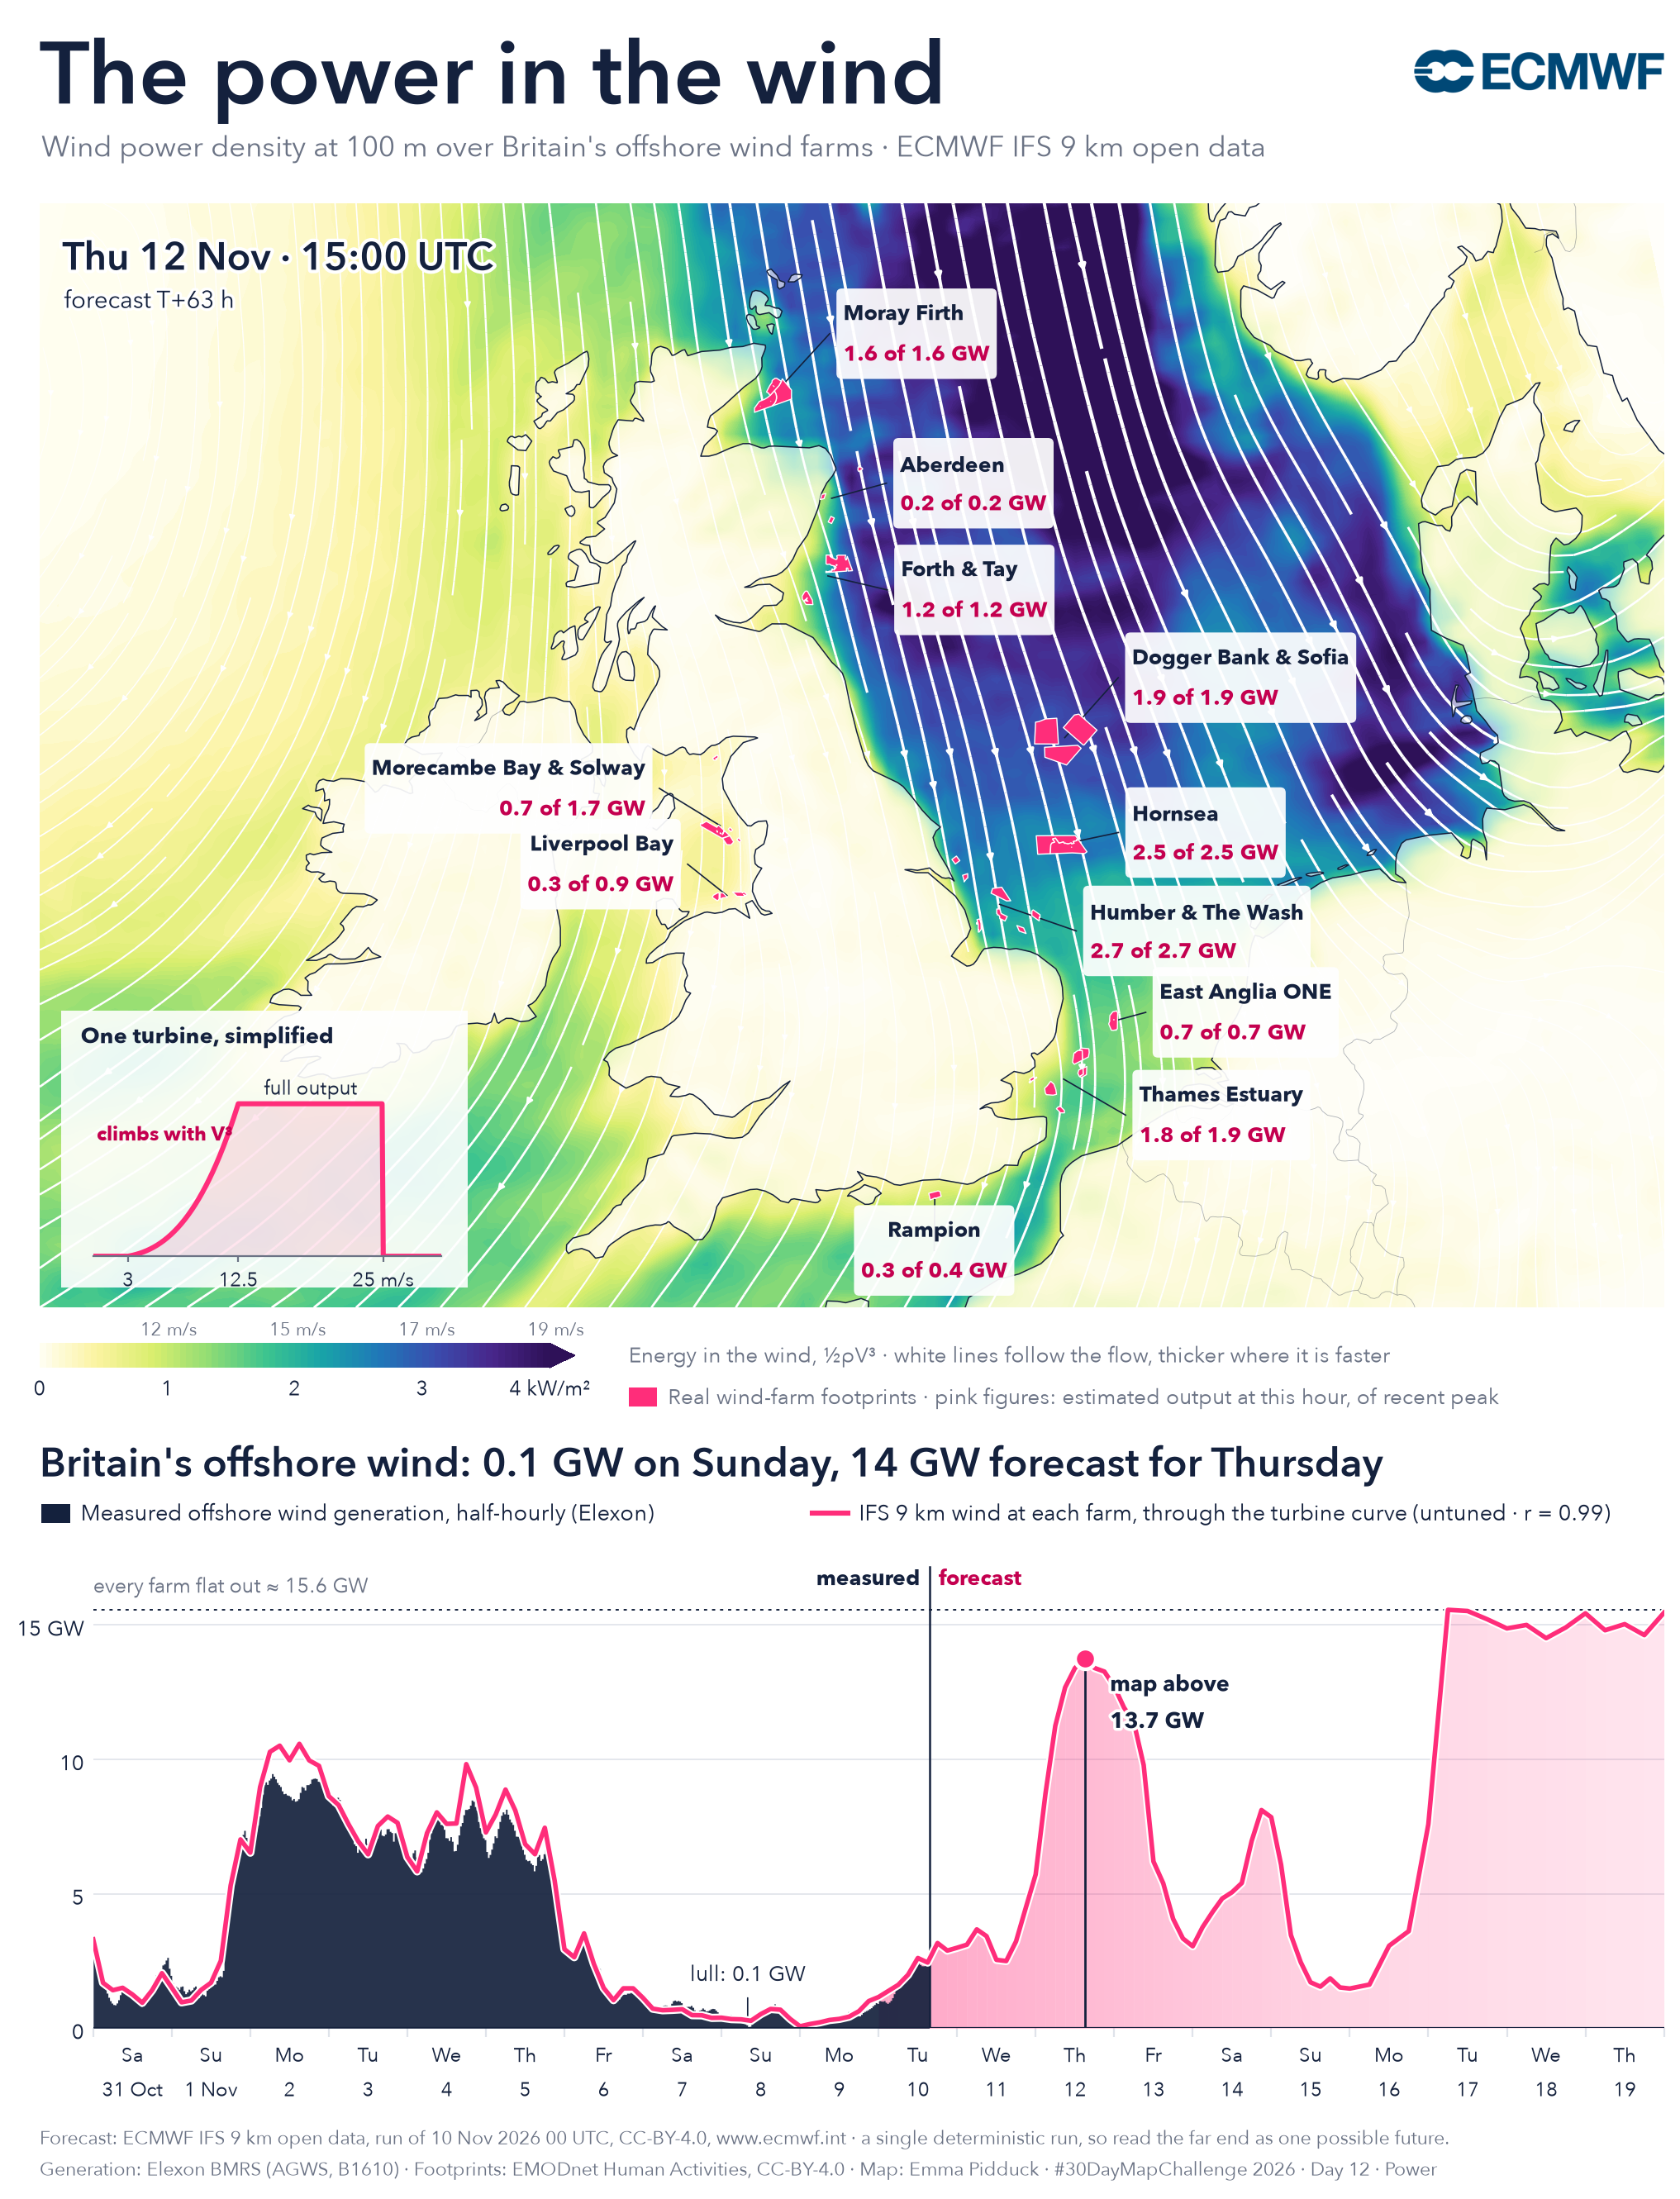

In [9]:
PC = ccrs.PlateCarree()
PROJ = ccrs.LambertConformal(central_longitude=-1.5, central_latitude=54.8, standard_parallels=(50, 59))
LAND = cfeature.NaturalEarthFeature("physical", "land", "50m")
halo = lambda w=2.4: [pe.withStroke(linewidth=w, foreground="white")]
when = lambda t, f: t.astype("datetime64[s]").astype(dt.datetime).strftime(f)
days_from_run = lambda t: (np.asarray(t, "datetime64[s]") - BASE.astype("datetime64[s]")) / np.timedelta64(1, "D")

def poster(k, path=None, dpi=200):
    W, H = 10.8, 13.5                                                   # 4:5, the tall social format
    fig = plt.figure(figsize=(W, H), dpi=dpi); fig.patch.set_facecolor(BG)

    # ---- header
    fig.text(0.045, 0.957, "The power in the wind", color=INK, fontsize=38, fontfamily=TITLEF, va="center")
    fig.text(0.046, 0.925, "Wind power density at 100 m over Britain's offshore wind farms · ECMWF IFS 9 km open data",
             color=MUT, fontsize=12.6, va="center")
    try:
        lg = fig.add_axes([0.815, 0.938, 0.14, 0.042]); lg.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); lg.axis("off")
    except FileNotFoundError:
        pass

    # ---- map: the frame is set in projected metres so it fills its box exactly
    box = [0.045, 0.405, 0.91, 0.495]
    ax = fig.add_axes(box, projection=PROJ)
    half_h = 575e3; half_w = half_h * (box[2] * W) / (box[3] * H)
    ax.set_xlim(-half_w, half_w); ax.set_ylim(-half_h, half_h); ax.set_facecolor(CMAP(0.0))
    P = 0.5 * RHO * SPD[k] ** 3 / 1000.0                                # wind power density, kW/m²
    cf = ax.contourf(LON, LAT, P, levels=np.linspace(0, 4, 81), cmap=CMAP, extend="max", transform=PC, zorder=0)
    s = 3                                                               # thin the grid for the flow lines
    ax.streamplot(LON[::s], LAT[::s], U[k][::s, ::s], V[k][::s, ::s], transform=PC, density=(2.6, 1.9), color="white",
                  linewidth=0.25 + 1.5 * np.clip(SPD[k][::s, ::s] / 22.0, 0, 1) ** 1.5, arrowsize=0.55, arrowstyle="-|>", zorder=1)
    ax.add_feature(LAND, facecolor="white", alpha=0.62, edgecolor="none", zorder=2)        # veil the land, keep the field
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.55, zorder=3)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor=INK, linewidth=0.3, alpha=0.35, zorder=3)
    ax.spines["geo"].set_visible(False)
    ax.add_geometries(list(SHAPE.values()), crs=PC, facecolor=HOT, edgecolor="white", linewidth=0.5, zorder=5)

    geo = PC._as_mpl_transform(ax)
    for name, members, lo, la, ha in GROUPS:
        gw, cap = sum(EST[f][k] for f in members), sum(CAP[f] for f in members)
        wts = [CAP[f] for f in members]
        cx, cy = np.average([XY[f][0] for f in members], weights=wts), np.average([XY[f][1] for f in members], weights=wts)
        ax.plot([cx, lo], [cy, la], color=INK, lw=0.6, transform=PC, zorder=4)
        dx = {"left": 6, "right": -6, "center": 0}[ha]; figures = f"{gw:.1f} of {cap:.1f} GW"
        kw = dict(xy=(lo, la), xycoords=geo, xytext=(dx, 0), textcoords="offset points", ha=ha, va="center",
                  fontweight="bold", linespacing=1.3)
        ax.annotate(f"{name}\n{figures}", color="none", fontsize=9.4, zorder=6, **kw,            # invisible text sizes the chip
                    bbox=dict(boxstyle="round,pad=0.32,rounding_size=0.25", fc="white", ec="none", alpha=0.93))
        ax.annotate(f"{name}\n", color=INK, fontsize=9.4, zorder=7, **kw)
        ax.annotate(f"\n{figures}", color=DEEP, fontsize=9.2, zorder=7, **kw)

    lead = int((T[k] - BASE) / np.timedelta64(1, "h"))
    kind = f"forecast T+{lead} h" if lead > 0 else ("start of the forecast run" if lead == 0 else "as the model saw it at the time")
    ax.text(0.014, 0.975, when(T[k], "%a %-d %b · %H:%M UTC"), transform=ax.transAxes, fontsize=17, color=INK,
            fontfamily=TITLEF, va="top", path_effects=halo(3), zorder=8)
    ax.text(0.015, 0.927, kind, transform=ax.transAxes, fontsize=10.5, color=INK, va="top", path_effects=halo(2.5), zorder=8)

    # ---- the turbine curve, on a card in the quiet corner of the map
    fig.add_artist(plt.Rectangle((0.057, 0.414), 0.228, 0.124, transform=fig.transFigure, fc="white", ec="none", alpha=0.9, zorder=8))
    fig.text(0.068, 0.5235, "One turbine, simplified", fontsize=9.8, fontweight="bold", color=INK, zorder=10)
    pc = fig.add_axes([0.075, 0.428, 0.195, 0.082]); pc.set_zorder(9); pc.patch.set_alpha(0)
    vv = np.linspace(0, 30, 301)
    pc.plot(vv, power_curve(vv), color=HOT, lw=2.2); pc.fill_between(vv, 0, power_curve(vv), color=HOT, alpha=0.12, lw=0)
    pc.set_xlim(0, 30); pc.set_ylim(0, 1.2); pc.set_yticks([]); pc.set_xticks([CUT_IN, RATED, CUT_OUT])
    pc.set_xticklabels([f"{CUT_IN:g}", f"{RATED:g}", f"{CUT_OUT:g} m/s"], fontsize=8.6, color=INK)
    pc.tick_params(length=2.5, color=MUT, pad=2)
    for side in ("top", "right", "left"): pc.spines[side].set_visible(False)
    pc.spines["bottom"].set_color(MUT)
    pc.text(0.3, 0.80, "cube law", fontsize=8.6, color=DEEP, fontweight="bold", va="center")
    pc.text((RATED + CUT_OUT) / 2, 1.06, "full output", fontsize=8.6, color=INK, ha="center")

    # ---- key row under the map
    cax = fig.add_axes([0.045, 0.378, 0.30, 0.011])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="max", ticks=[0, 1, 2, 3, 4])
    cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=9, colors=INK, pad=3)
    cb.ax.set_xticklabels(["0", "1", "2", "3", "4 kW/m²"])
    for p in (1, 2, 3, 4):                                              # the same scale read as wind speed
        fig.text(0.045 + 0.30 * p / 4 * (40 / 41.5), 0.3925, f"{(2000 * p / RHO) ** (1 / 3):.0f} m/s", fontsize=8, color=MUT, ha="center")
    fig.text(0.375, 0.3835, "Energy in the wind, ½ρV³ · white lines follow the flow, thicker where it is faster",
             fontsize=9.4, color=MUT, va="center")
    fig.add_artist(plt.Rectangle((0.375, 0.3605), 0.016, 0.0085, transform=fig.transFigure, fc=HOT, ec="none"))
    fig.text(0.397, 0.3648, "Real wind-farm footprints · pink figures: estimated output at this hour, of recent peak",
             fontsize=9.4, color=MUT, va="center")

    # ---- timeline
    lull, peak = int(np.argmin(OV)), K0 + int(np.argmax(TOT[K0:K0 + 41]))
    fig.text(0.045, 0.335, f"Britain's offshore wind: {OV[lull]:.1f} GW on {when(OT[lull], '%A')}, "
             f"{TOT[peak]:.0f} GW forecast for {when(T[peak], '%A')}", color=INK, fontsize=17.5, fontfamily=TITLEF, va="center")
    fig.add_artist(plt.Rectangle((0.046, 0.3085), 0.016, 0.0085, transform=fig.transFigure, fc=INK, ec="none"))
    fig.text(0.068, 0.3128, "Measured offshore wind generation, half-hourly (Elexon)", fontsize=9.8, color=INK, va="center")
    fig.add_artist(plt.Line2D([0.478, 0.498], [0.3128, 0.3128], transform=fig.transFigure, color=HOT, lw=2.2))
    fig.text(0.504, 0.3128, f"IFS 9 km wind at each farm, through the turbine curve (untuned · r = {R:.2f})",
             fontsize=9.8, color=INK, va="center")

    tl = fig.add_axes([0.075, 0.082, 0.88, 0.212])
    tl.fill_between(days_from_run(OT), 0, OV, color=INK, lw=0, alpha=0.92, step="post", zorder=2)
    xf, yf = days_from_run(T[K0:]), TOT[K0:]
    for i in range(len(xf) - 1):                                        # forecast fill fades with lead time
        tl.fill_between(xf[i:i + 2], 0, yf[i:i + 2], color=HOT, lw=0, alpha=0.42 - 0.30 * i / (len(xf) - 1), zorder=1)
    tl.plot(days_from_run(T), TOT, color=HOT, lw=2.0, zorder=4, solid_joinstyle="round",
            path_effects=[pe.withStroke(linewidth=3.6, foreground="white")])
    tl.axhline(FLEET, color=INK, lw=0.7, ls=(0, (2, 3)), zorder=0)
    tl.text(-DAYS_BACK, FLEET + 0.35, f"every farm flat out ≈ {FLEET:.1f} GW", fontsize=9, color=MUT, va="bottom")
    xn = float(days_from_run(NOW))
    tl.axvline(xn, color=INK, lw=0.9, zorder=3, ymax=0.975)
    tl.text(xn - 0.12, FLEET * 1.075, "measured", fontsize=9.4, color=INK, fontweight="bold", ha="right", va="center")
    tl.text(xn + 0.12, FLEET * 1.075, "forecast", fontsize=9.4, color=DEEP, fontweight="bold", ha="left", va="center")
    tl.annotate(f"lull: {OV[lull]:.1f} GW", (float(days_from_run(OT[lull])), OV[lull]), xytext=(0, 20), textcoords="offset points",
                fontsize=9.2, color=INK, ha="center", arrowprops=dict(arrowstyle="-", color=INK, lw=0.6, shrinkB=2))
    xk = float(days_from_run(T[k]))                                     # where the map sits in time
    tl.plot([xk, xk], [0, TOT[k]], color=INK, lw=1.0, zorder=5)
    tl.plot(xk, TOT[k], "o", ms=9, mfc=HOT, mec="white", mew=1.6, zorder=6)
    if k < K0:                                                          # over the dark measured area: label sits above the dot
        tl.annotate(f"map above · {TOT[k]:.1f} GW", (xk, max(TOT[k], OV[np.abs(OT - T[k]).argmin()])), xytext=(0, 11),
                    textcoords="offset points", fontsize=9.6, color=INK, fontweight="bold", ha="center", va="bottom",
                    zorder=7, path_effects=halo(2.6))
    else:
        right = xk < 6.5
        tl.annotate(f"map above\n{TOT[k]:.1f} GW", (xk, TOT[k]), xytext=(11 if right else -11, -4), textcoords="offset points",
                    fontsize=9.6, color=INK, fontweight="bold", ha="left" if right else "right", va="top", zorder=7,
                    path_effects=halo(2.6), linespacing=1.15)
    tl.set_xlim(-DAYS_BACK, 10); tl.set_ylim(0, FLEET * 1.13)
    tl.set_yticks([0, 5, 10, 15]); tl.set_yticklabels(["0", "5", "10", "15 GW"], fontsize=9.4, color=INK)
    offs = np.arange(-DAYS_BACK, 10)
    dates = [(BASE.astype("datetime64[D]") + int(d)).astype(dt.date) for d in offs]
    tl.set_xticks(np.arange(-DAYS_BACK, 11)); tl.set_xticklabels([])
    tl.set_xticks(offs + 0.5, minor=True)
    tl.set_xticklabels([f"{d:%a}"[:2] + f"\n{d.day}" + (f" {d:%b}" if (i == 0 or d.day == 1) else "") for i, d in enumerate(dates)],
                       minor=True, fontsize=8.8, color=INK, linespacing=1.25)
    tl.tick_params(axis="x", which="major", length=4, color=RULE); tl.tick_params(axis="x", which="minor", length=0, pad=4)
    tl.tick_params(axis="y", length=0, pad=4)
    tl.grid(axis="y", color=RULE, lw=0.6, zorder=0); tl.set_axisbelow(True)
    for spine in tl.spines.values(): spine.set_visible(False)
    tl.axhline(0, color=INK, lw=0.8, zorder=6)

    # ---- footer
    fig.text(0.045, 0.030, f"Forecast: ECMWF IFS 9 km open data, run of {when(BASE, '%-d %b %Y %H')} UTC, CC-BY-4.0, www.ecmwf.int · "
             "a single deterministic run, so read the far end as one possible future.", fontsize=8.3, color=MUT)
    fig.text(0.045, 0.016, "Generation: Elexon BMRS (AGWS, B1610) · Footprints: EMODnet Human Activities, CC-BY-4.0 · Map: Emma Pidduck · "
             "#30DayMapChallenge 2026 · Day 12 · Power", fontsize=8.3, color=MUT)
    if path:
        fig.savefig(path, facecolor=BG, dpi=dpi)
    return fig

fig = poster(K_MAP, PNG)
plt.show()

## Twenty days in motion

The still is one hour. The animation walks the marker along the whole timeline: first the ten
days already lived, where the pink estimate can be judged against the dark measured area, then
straight on through the forecast. Watch each cluster's figure tick up as a band of wind crosses
it, and the Irish Sea farms lag or lead the North Sea ones as fronts go through.

Frames are written to `_build/` and stitched with `ffmpeg` if it is installed (an MP4 for
posting, plus a lighter GIF for this page); otherwise `imageio` writes the GIF alone.

In [10]:
FRAMES = list(range(0, K0, 2)) + list(range(K0, len(T)))        # 6-hourly through the past, every step of the forecast
frame_dir = "_build/day12_frames"
shutil.rmtree(frame_dir, ignore_errors=True); os.makedirs(frame_dir)
for i, k in enumerate(FRAMES):
    plt.close(poster(k, f"{frame_dir}/f{i:03d}.png", dpi=100))          # 1080 × 1350

if shutil.which("ffmpeg"):
    run = lambda *a: subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", "8", "-i", f"{frame_dir}/f%03d.png", *a], check=True)
    run("-vf", "tpad=stop_mode=clone:stop_duration=2", "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "20", MP4)
    run("-vf", "tpad=stop_mode=clone:stop_duration=2,scale=640:-1:flags=lanczos,split[a][b];[a]palettegen=max_colors=128[p];[b][p]paletteuse=dither=bayer:bayer_scale=4", GIF)
else:
    import imageio.v2 as imageio
    frames = [imageio.imread(f"{frame_dir}/f{i:03d}.png")[::2, ::2, :3] for i in range(len(FRAMES))]
    imageio.mimsave(GIF, frames, duration=[0.125] * (len(frames) - 1) + [2.0], loop=0)
print(len(FRAMES), "frames →", ", ".join(f"{f} ({os.path.getsize(f) / 1e6:.1f} MB)" for f in (MP4, GIF) if os.path.exists(f)))

105 frames → day12_power_forecast.mp4 (5.2 MB), day12_power_forecast.gif (8.8 MB)


![Twenty days of wind over Britain's offshore wind farms, measured and forecast — ECMWF IFS 9 km open data](day12_power_forecast.gif)

*Ten days measured, ten days forecast, at the model's 9 km grid. Crisper MP4:
[`day12_power_forecast.mp4`](day12_power_forecast.mp4).*

## Note

**It works better than it has any right to.** A three-number turbine curve on a 9 km global
forecast follows the measured output of an entire national fleet closely (the correlation is
printed above and on the plate). Wind power is mostly weather, and the weather is forecastable.

**Where it misses, it misses high**, and for honest reasons: turbines shadow each other (wakes),
some are always down for maintenance, and in a gale the grid sometimes cannot carry everything
the Scottish farms could make, so they are paid to turn down. That last effect shows up in the
capacities learned from the data: farms north of the border rarely reach their nameplate.

**The cube law does the storytelling.** The gap between a lull and a gale on the timeline is not
a doubling, it is the difference between a fleet idling near zero and one close to flat out, a few
days apart. That swing is what the rest of the electricity system has to absorb, and it is why a
good forecast of it is worth real money.

**What to trust.** The first three to five days of the pink forecast are solid guidance. Beyond
that this is a single deterministic run; the ensemble would show the spread, and would be the
right tool for anything that mattered.

*Day 2 Lines · Day 6 Vintage · Day 20 Hexagons · Day 22 Projections · Day 26 Water · Day 27 New
tool · Day 28 Feeling.*